# FPL Data Exploration (2024-25 season)
Exploring historical gameweek data before building a points prediction model.

In [43]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

## Load data
Historical data: one row per player per match ([vaastav/Fantasy-Premier-League](https://github.com/vaastav/Fantasy-Premier-League)).

In [44]:
url = "https://raw.githubusercontent.com/vaastav/Fantasy-Premier-League/master/data/2024-25/gws/merged_gw.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

(27605, 49)


,name,position,team,xP,assists,bonus,bps,clean_sheets,creativity,element,expected_assists,expected_goal_involvements,expected_goals,expected_goals_conceded,fixture,goals_conceded,goals_scored,ict_index,influence,kickoff_time,minutes,mng_clean_sheets,mng_draw,mng_goals_scored,mng_loss,mng_underdog_draw,mng_underdog_win,mng_win,modified,opponent_team,own_goals,penalties_missed,penalties_saved,red_cards,round,saves,selected,starts,team_a_score,team_h_score,threat,total_points,transfers_balance,transfers_in,transfers_out,value,was_home,yellow_cards,GW
0,Alex Scott,MID,Bournemouth,1.6,0,0,11,0,12.8,77,0.01,0.01,0.0,1.02,6,1,0,3.6,22.8,2024-08-17T14:00:00Z,62,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,16,0,0,0,0,1,0,4339,1,1,1,0.0,2,0,0,0,50,False,0,1
1,Carlos Miguel dos Santos Pereira,GK,Nott'm Forest,2.2,0,0,0,0,0.0,427,0.00,0.00,0.0,0.00,6,0,0,0.0,0.0,2024-08-17T14:00:00Z,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,3,0,0,0,0,1,0,33324,0,1,1,0.0,0,0,0,0,45,True,0,1
2,Tomiyasu Takehiro,DEF,Arsenal,0.0,0,0,0,0,0.0,22,0.00,0.00,0.0,0.00,2,0,0,0.0,0.0,2024-08-17T14:00:00Z,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,20,0,0,0,0,1,0,8462,0,0,2,0.0,0,0,0,0,50,True,0,1
3,Malcolm Ebiowei,MID,Crystal Palace,0.0,0,0,0,0,0.0,197,0.00,0.00,0.0,0.00,8,0,0,0.0,0.0,2024-08-18T13:00:00Z,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,4,0,0,0,0,1,0,716,0,1,2,0.0,0,0,0,0,45,False,0,1
4,Ben Brereton Díaz,MID,Southampton,1.0,0,0,-2,0,14.0,584,0.02,0.32,0.3,0.25,5,1,0,3.3,2.6,2024-08-17T14:00:00Z,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,15,0,0,0,0,1,0,66244,1,0,1,16.0,1,0,0,0,55,False,1,1


In [45]:
df.columns.tolist()

['name',
 'position',
 'team',
 'xP',
 'assists',
 'bonus',
 'bps',
 'clean_sheets',
 'creativity',
 'element',
 'expected_assists',
 'expected_goal_involvements',
 'expected_goals',
 'expected_goals_conceded',
 'fixture',
 'goals_conceded',
 'goals_scored',
 'ict_index',
 'influence',
 'kickoff_time',
 'minutes',
 'mng_clean_sheets',
 'mng_draw',
 'mng_goals_scored',
 'mng_loss',
 'mng_underdog_draw',
 'mng_underdog_win',
 'mng_win',
 'modified',
 'opponent_team',
 'own_goals',
 'penalties_missed',
 'penalties_saved',
 'red_cards',
 'round',
 'saves',
 'selected',
 'starts',
 'team_a_score',
 'team_h_score',
 'threat',
 'total_points',
 'transfers_balance',
 'transfers_in',
 'transfers_out',
 'value',
 'was_home',
 'yellow_cards',
 'GW']

Live data from the official FPL API: one row per player, current season totals.

In [46]:
data = requests.get("https://fantasy.premierleague.com/api/bootstrap-static/").json()
players = pd.DataFrame(data["elements"])
teams = pd.DataFrame(data["teams"])
print(players.shape, teams.shape)
players[["web_name", "team", "element_type", "now_cost", "total_points", "form"]].head()

(669, 109) (20, 22)


,web_name,team,element_type,now_cost,total_points,form
0,Raya,1,1,62,49,6.3
1,Arrizabalaga,1,1,49,0,0.0
2,Meslier,1,1,49,0,0.0
3,Gabriel,1,2,79,52,9.0
4,J.Timber,1,2,65,3,0.7


## 1. How many players and gameweeks?

In [47]:
print(f"Unique players: {df['element'].nunique()}")
print(f"Unique gameweeks: {df['GW'].nunique()}")

Unique players: 804
Unique gameweeks: 38


804 players appear across 38 gameweeks — more than the ~670 registered at any one time, because of mid-season transfers.

## 2. How are points distributed?

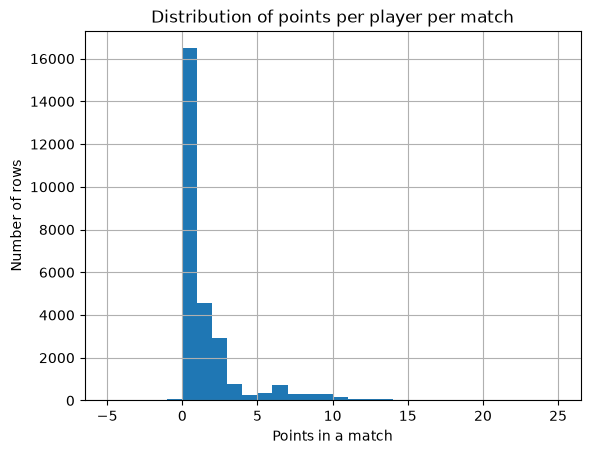

In [48]:
df["total_points"].hist(bins=30)
plt.xlabel("Points in a match")
plt.ylabel("Number of rows")
plt.title("Distribution of points per player per match")
plt.show()

In [49]:
df["total_points"].value_counts(normalize=True).head(10)

total_points
0    0.596848
1    0.165115
2    0.106539
3    0.027893
6    0.026336
5    0.013512
7    0.011809
8    0.010578
9    0.010252
4    0.008730
Name: proportion, dtype: float64

0 is by far the most common score (~60% of rows). Scores of 10+ are under 2%. 4 points is unusually rare because of how FPL scoring stacks (2 for playing + chunks like 3, 4, or 5 for events).

## 3. How often do players not play?

In [50]:
pct_zero_minutes = (df["minutes"] == 0).mean() * 100
print(f"Rows with 0 minutes: {pct_zero_minutes:.1f}%")

Rows with 0 minutes: 58.1%


58% of rows have 0 minutes, so nearly all 0-point rows come from players not playing at all.

## 4. One player's season: João Pedro

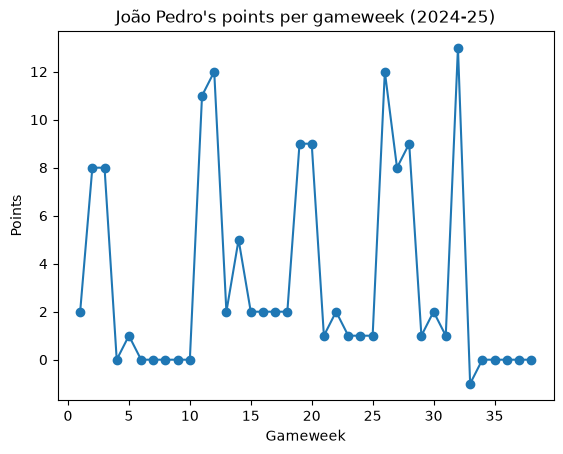

In [51]:
joao_pedro = df[df["name"] == "João Pedro Junqueira de Jesus"]
jp_points_per_gw = joao_pedro.groupby("GW")["total_points"].sum()  # sum handles double gameweeks

plt.plot(jp_points_per_gw.index, jp_points_per_gw.values, marker="o")
plt.xlabel("Gameweek")
plt.ylabel("Points")
plt.title("João Pedro's points per gameweek (2024-25)")
plt.show()

Very spiky: occasional hauls (11–13) surrounded by 1–2 point weeks, plus runs of zeros from injury/suspension. A model can't predict *which* week a haul comes — it should predict the *expected* points.

## 5. Top 10 scorers of the season

In [52]:
df.groupby("name")["total_points"].sum().nlargest(10)

name
Mohamed Salah     344
Bryan Mbeumo      236
Cole Palmer       214
Alexander Isak    211
Chris Wood        200
Jarrod Bowen      193
Ollie Watkins     186
Yoane Wissa       185
Luis Díaz         183
Erling Haaland    181
Name: total_points, dtype: int64

Salah (344) was over 100 points clear of second place, matching his record 2024-25 season — a good sanity check that the data is correct.

## Key takeaways
- Whether a player plays is the biggest driver of points.
- Opponent strength matters.
- Points are spiky, so we predict expected points, and must avoid a model that just predicts 0.